# Hazelnut Anomaly Detection
### Unsupervised visual anomaly detection for industrial quality control

This notebook builds an anomaly detection system for hazelnut inspection, using the [MVTec AD](https://www.mvtec.com/company/research/datasets/mvtec-ad) dataset. The model learns what a *normal* (defect-free) hazelnut looks like using only clean samples, then flags anything that deviates from it. It also produces pixel-level heatmaps that show *where* the defect is.

**Pipeline overview:**
1. **Part 0** — Setup, data loading, and preprocessing
2. **Part 1** — Baseline: whole-image features + nearest-neighbor scoring
3. **Part 2** — Pixel-level localization with spatial features (heatmaps)
4. **Part 3** — Multi-layer feature fusion for sharper localization and better detection

---
## Part 0 — Setup and data

Import libraries, define helper functions, and load the hazelnut images.

In [1]:
import torch
import torch.nn.functional as F
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms, models
from sklearn.metrics import roc_auc_score, roc_curve


In [2]:
IMG_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

def list_images(folder):
    """Return sorted paths of all image files in a folder, any common format."""
    folder = Path(folder)
    paths = sorted(p for p in folder.iterdir()
                   if p.suffix.lower() in IMG_EXTENSIONS)
    return paths

In [3]:
train_good_dir = Path("hazelnut/train/good")
image_paths = list_images(train_good_dir)

print("Number of training images:", len(image_paths))
print("First image path:", image_paths[0])

Number of training images: 391
First image path: hazelnut\train\good\000.png


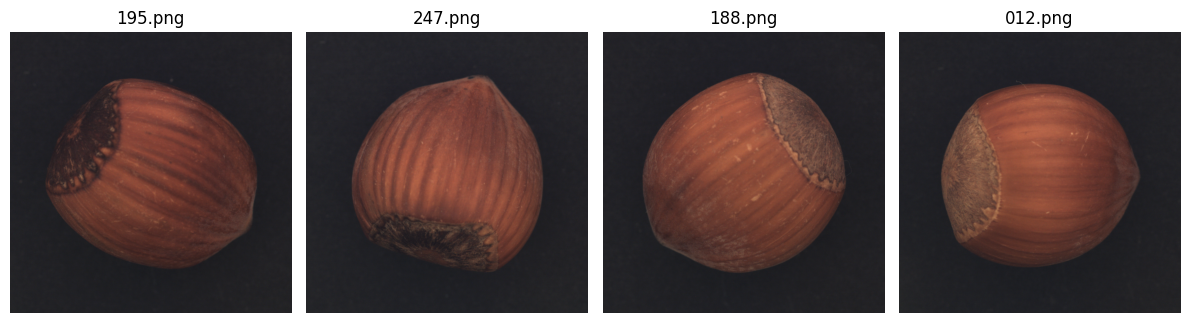

In [4]:
# Pick 4 random images 
random_paths = np.random.choice(image_paths, size=4, replace=False)

fig, axes = plt.subplots(1, 4, figsize=(12, 6))

for ax, img_path in zip(axes.flat, random_paths):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(img_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
# Define the preprocessing pipeline: resize, convert to tensor, normalize
transform = transforms.Compose([
    transforms.Resize((224, 224)),                 # make every image 224x224
    transforms.ToTensor(),                          # convert to tensor, scale pixels to [0, 1]
    transforms.Normalize(                           # normalize with ImageNet stats
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

---
## Part 1 — Baseline: whole-image nearest neighbor

Each image is turned into a single feature vector using ResNet18 (with its classification head removed). A memory bank of normal features is built from the training set. A test image is scored by its distance to the nearest normal neighbor: close means normal, far means anomalous.

In [6]:
# Load a pretrained ResNet18 and turn it into a feature extractor
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load ResNet18 pretrained on ImageNet
resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Remove the final classification layer: keep everything except the last "fc" layer
feature_extractor = torch.nn.Sequential(*list(resnet.children())[:-1])

# Set to evaluation mode (we are not training) and move to GPU
feature_extractor.eval()
feature_extractor.to(device)

print("Feature extractor ready on:", device)

Feature extractor ready on: cuda


In [7]:
def extract_features(img_path):
    """Load one image, preprocess it, and return its 512-dim feature vector."""
    img = Image.open(img_path).convert("RGB")
    input_tensor = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        features = feature_extractor(input_tensor)
    return features.flatten().cpu()

In [8]:
# Extract features for ALL 391 normal training images
train_features = []

for i, img_path in enumerate(image_paths):
    vec = extract_features(img_path)
    train_features.append(vec)
    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1} / {len(image_paths)} images")

# Stack all vectors into a single tensor: shape [391, 512]
train_features = torch.stack(train_features)

print("\nDone!")
print("Training feature bank shape:", train_features.shape)

Processed 50 / 391 images
Processed 100 / 391 images
Processed 150 / 391 images
Processed 200 / 391 images
Processed 250 / 391 images
Processed 300 / 391 images
Processed 350 / 391 images

Done!
Training feature bank shape: torch.Size([391, 512])


In [9]:
# Look at what's inside the test folder
test_dir = Path("hazelnut/test")

test_categories = sorted([p.name for p in test_dir.iterdir() if p.is_dir()])
print("Test categories:", test_categories)

for cat in test_categories:
    n = len(list_images(test_dir / cat))
    print(f"  {cat}: {n} images")

Test categories: ['crack', 'cut', 'good', 'hole', 'print']
  crack: 18 images
  cut: 17 images
  good: 40 images
  hole: 18 images
  print: 17 images


In [10]:
# Score ALL test images, keeping track of their true category
test_scores = []   # anomaly score of each test image
test_labels = []   # 0 = good (normal), 1 = defective (anomaly)

for cat in test_categories:
    cat_paths = list_images(test_dir / cat)
    for img_path in cat_paths:
        vec = extract_features(img_path)
        dists = torch.norm(train_features - vec, dim=1)
        score = dists.min().item()
        test_scores.append(score)
        test_labels.append(0 if cat == "good" else 1)

# Convert to tensors for easy math
test_scores = torch.tensor(test_scores)
test_labels = torch.tensor(test_labels)

print("Total test images scored:", len(test_scores))
print("Normal (good):", (test_labels == 0).sum().item())
print("Defective:", (test_labels == 1).sum().item())

Total test images scored: 110
Normal (good): 40
Defective: 70


In [11]:
# Split scores by their true label
good_scores = test_scores[test_labels == 0]
defect_scores = test_scores[test_labels == 1]

print(f"GOOD  scores -> mean: {good_scores.mean():.3f}, min: {good_scores.min():.3f}, max: {good_scores.max():.3f}")
print(f"DEFECT scores -> mean: {defect_scores.mean():.3f}, min: {defect_scores.min():.3f}, max: {defect_scores.max():.3f}")

GOOD  scores -> mean: 8.529, min: 6.553, max: 10.600
DEFECT scores -> mean: 12.097, min: 7.950, max: 17.542


In [12]:
# AUC needs: true labels (0/1) and the scores. Convert tensors to plain lists.
auc = roc_auc_score(test_labels.numpy(), test_scores.numpy())

print(f"ROC-AUC: {auc:.4f}")

ROC-AUC: 0.9625


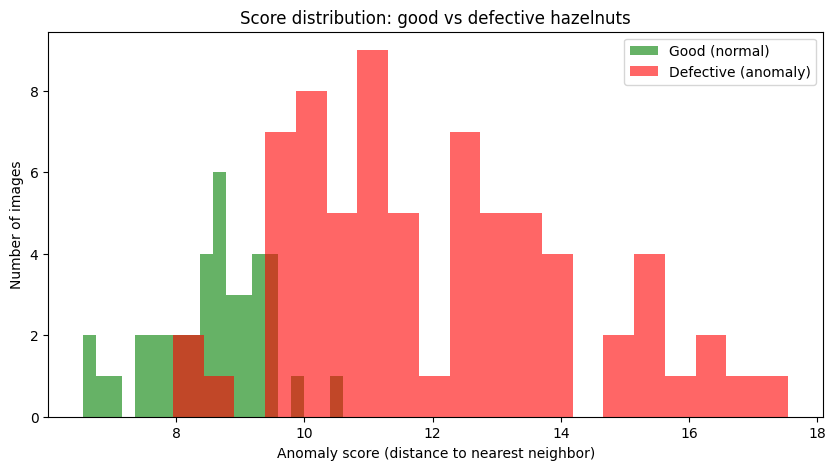

In [13]:
# Separate scores by true label (we already did this earlier, but redo for clarity)
good_scores = test_scores[test_labels == 0].numpy()
defect_scores = test_scores[test_labels == 1].numpy()

plt.figure(figsize=(10, 5))

# Two overlapping histograms
plt.hist(good_scores, bins=20, alpha=0.6, label="Good (normal)", color="green")
plt.hist(defect_scores, bins=20, alpha=0.6, label="Defective (anomaly)", color="red")

plt.xlabel("Anomaly score (distance to nearest neighbor)")
plt.ylabel("Number of images")
plt.title("Score distribution: good vs defective hazelnuts")
plt.legend()
plt.show()

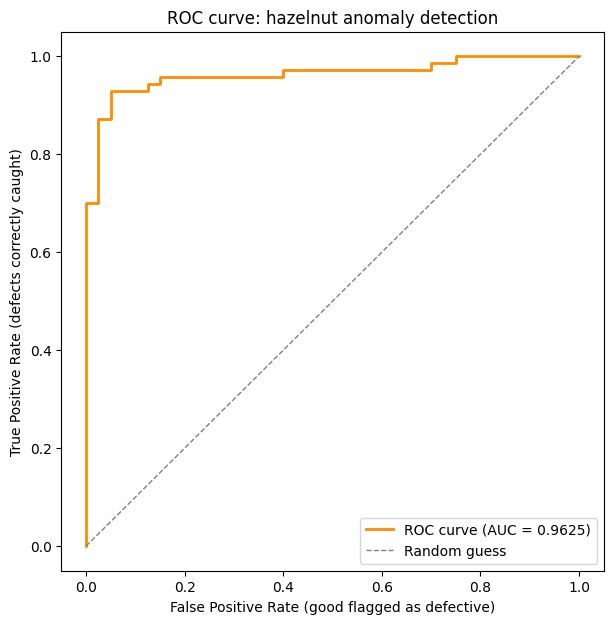

In [14]:
# Compute the ROC curve: false positive rate, true positive rate, at every threshold
fpr, tpr, thresholds = roc_curve(test_labels.numpy(), test_scores.numpy())
auc = roc_auc_score(test_labels.numpy(), test_scores.numpy())

plt.figure(figsize=(7, 7))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], color="gray", lw=1, linestyle="--", label="Random guess")

plt.xlabel("False Positive Rate (good flagged as defective)")
plt.ylabel("True Positive Rate (defects correctly caught)")
plt.title("ROC curve: hazelnut anomaly detection")
plt.legend()
plt.show()

---
## Part 2 — Pixel-level localization (heatmaps)

The baseline only says *whether* an image is defective, not *where*. To localize the defect, we keep the spatial grid of ResNet features (7x7) instead of collapsing it to a single vector. Each of the 49 regions gets its own anomaly score, which we turn into a heatmap.

In [15]:
# Spatial feature extractor: keep the 7x7 spatial grid instead of collapsing to a vector
# We remove the last TWO layers of ResNet18: the avgpool (7x7 -> 1x1) and the fc (classifier)
spatial_extractor = torch.nn.Sequential(*list(resnet.children())[:-2])
spatial_extractor.eval()
spatial_extractor.to(device)

# Test it on one image to see the output shape
img = Image.open(image_paths[0]).convert("RGB")
input_tensor = transform(img).unsqueeze(0).to(device)

with torch.no_grad():
    spatial_feat = spatial_extractor(input_tensor)

print("Spatial feature shape:", spatial_feat.shape)

Spatial feature shape: torch.Size([1, 512, 7, 7])


In [16]:
# Reshape [1, 512, 7, 7] -> [49, 512]: one row per spatial region
def extract_spatial_features(img_path):
    """Return spatial features of one image as [num_regions, 512] = [49, 512]."""
    img = Image.open(img_path).convert("RGB")
    input_tensor = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        feat = spatial_extractor(input_tensor)   # [1, 512, 7, 7]

    # Remove batch dim, flatten spatial grid, and put regions first
    feat = feat.squeeze(0)          # [512, 7, 7]
    feat = feat.flatten(1)          # [512, 49]  -> merge the 7x7 into 49
    feat = feat.permute(1, 0)       # [49, 512]  -> swap: regions first, features second
    return feat.cpu()

# Test on one image
test_spatial = extract_spatial_features(image_paths[0])
print("Spatial feature shape:", test_spatial.shape)

Spatial feature shape: torch.Size([49, 512])


In [17]:
# Build the normal region bank: collect spatial features from ALL 391 training images
spatial_bank = []

for i, img_path in enumerate(image_paths):
    regions = extract_spatial_features(img_path)   # [49, 512] per image
    spatial_bank.append(regions)
    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1} / {len(image_paths)} images")

# Stack all region features into one big bank: [391*49, 512] = [19159, 512]
spatial_bank = torch.cat(spatial_bank, dim=0)

print("\nDone!")
print("Normal region bank shape:", spatial_bank.shape)

Processed 50 / 391 images
Processed 100 / 391 images
Processed 150 / 391 images
Processed 200 / 391 images
Processed 250 / 391 images
Processed 300 / 391 images
Processed 350 / 391 images

Done!
Normal region bank shape: torch.Size([19159, 512])


In [18]:
# Pick one CRACK test image
crack_path = list_images(test_dir / "crack")[0]

# Extract its 49 region features
crack_regions = extract_spatial_features(crack_path).to(device)   # [49, 512]

# Compute distance from each of the 49 regions to ALL 19159 bank regions
# cdist gives a [49, 19159] matrix: distance from every test region to every bank region
dists = torch.cdist(crack_regions, spatial_bank.to(device))       # [49, 19159]

# For each region, the anomaly score = distance to its NEAREST neighbor (min over the bank)
region_scores = dists.min(dim=1).values                           # [49]

print("Region scores shape:", region_scores.shape)
print("Min score:", region_scores.min().item())
print("Max score:", region_scores.max().item())
print("Mean score:", region_scores.mean().item())

Region scores shape: torch.Size([49])
Min score: 2.6939337253570557
Max score: 60.35689926147461
Mean score: 22.959102630615234


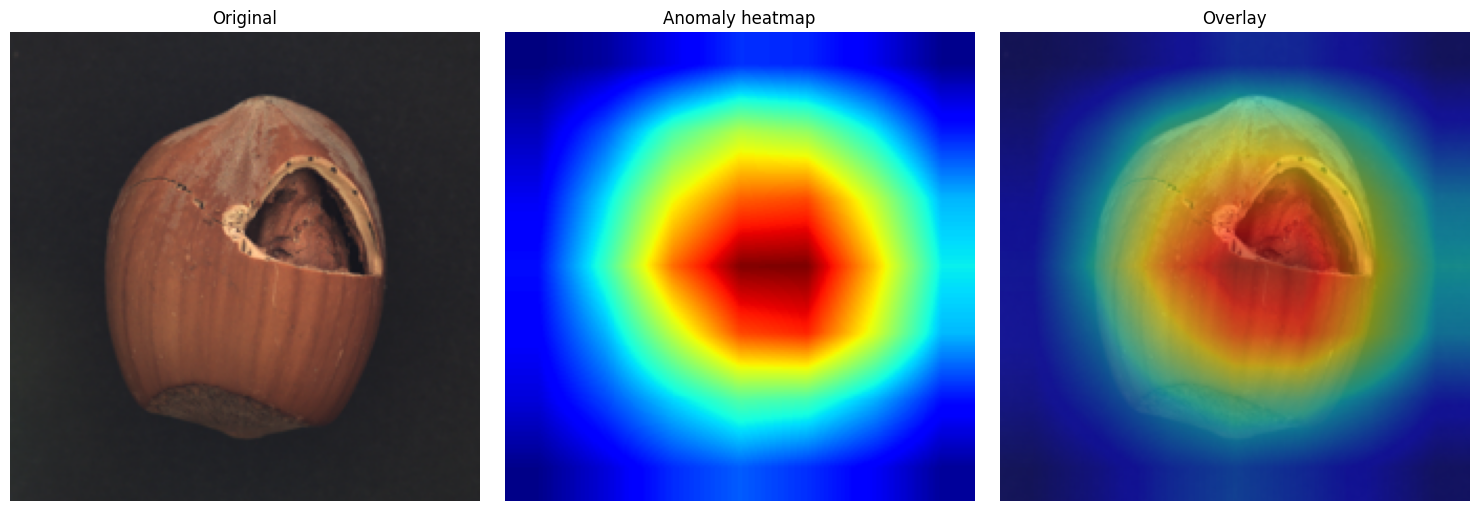

In [19]:
# 1. Reshape the 49 scores back into a 7x7 grid
score_map = region_scores.reshape(1, 1, 7, 7)   # [1, 1, 7, 7] for interpolate

# 2. Upsample 7x7 -> 224x224 with smooth interpolation
score_map = F.interpolate(score_map, size=(224, 224), mode="bilinear", align_corners=False)
score_map = score_map.squeeze().cpu().numpy()    # [224, 224]

# 3. Load the original image, resized to 224x224 to match
orig_img = Image.open(crack_path).convert("RGB").resize((224, 224))

# 4. Plot: original image + heatmap overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(orig_img)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(score_map, cmap="jet")
axes[1].set_title("Anomaly heatmap")
axes[1].axis("off")

axes[2].imshow(orig_img)
axes[2].imshow(score_map, cmap="jet", alpha=0.5)
axes[2].set_title("Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

---
## Part 3 — Multi-layer feature fusion

The 7x7 heatmap is coarse. To sharpen it, we combine features from two intermediate ResNet layers: `layer2` (fine spatial detail, 28x28) and `layer3` (richer semantics, 14x14). We align them to the same grid with interpolation and concatenate. Scoring each image by its **maximum** region score also stops small defects from being averaged away, which improves detection.

In [20]:
# We want intermediate outputs of ResNet: layer2 and layer3.
# A "hook" is a function that captures a layer's output as data flows through it.

# Reload a clean ResNet18 (feature extractor, full network this time)
resnet_full = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
resnet_full.eval()
resnet_full.to(device)

# Dictionary to store the captured outputs
captured = {}

def make_hook(name):
    def hook(module, input, output):
        captured[name] = output
    return hook

# Register hooks on layer2 and layer3
resnet_full.layer2.register_forward_hook(make_hook("layer2"))
resnet_full.layer3.register_forward_hook(make_hook("layer3"))

# Test: run one image through, see what shapes we captured
img = Image.open(image_paths[0]).convert("RGB")
input_tensor = transform(img).unsqueeze(0).to(device)

with torch.no_grad():
    _ = resnet_full(input_tensor)

print("layer2 output shape:", captured["layer2"].shape)
print("layer3 output shape:", captured["layer3"].shape)

layer2 output shape: torch.Size([1, 128, 28, 28])
layer3 output shape: torch.Size([1, 256, 14, 14])


In [21]:
def extract_fused_features(img_path):
    """Extract multi-layer fused spatial features: [28*28, 128+256] = [784, 384]."""
    img = Image.open(img_path).convert("RGB")
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        _ = resnet_full(input_tensor)   # runs the model, hooks fill `captured`

    f2 = captured["layer2"]   # [1, 128, 28, 28]
    f3 = captured["layer3"]   # [1, 256, 14, 14]

    # Align: upsample layer3 (14x14) to match layer2's 28x28 grid
    f3_up = F.interpolate(f3, size=(28, 28), mode="bilinear", align_corners=False)  # [1, 256, 28, 28]

    # Concatenate along the feature (channel) dimension: 128 + 256 = 384
    fused = torch.cat([f2, f3_up], dim=1)   # [1, 384, 28, 28]

    # Reshape to [num_regions, features] = [784, 384]
    fused = fused.squeeze(0).flatten(1).permute(1, 0)   # [784, 384]
    return fused.cpu()

# Test on one image
test_fused = extract_fused_features(image_paths[0])
print("Fused feature shape:", test_fused.shape)

Fused feature shape: torch.Size([784, 384])


In [22]:
# Build the fused region bank from ALL 391 training images
fused_bank = []

for i, img_path in enumerate(image_paths):
    regions = extract_fused_features(img_path)   # [784, 384] per image
    fused_bank.append(regions)
    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1} / {len(image_paths)} images")

fused_bank = torch.cat(fused_bank, dim=0)   # [391*784, 384] = [306544, 384]

print("\nDone!")
print("Fused region bank shape:", fused_bank.shape)

Processed 50 / 391 images
Processed 100 / 391 images
Processed 150 / 391 images
Processed 200 / 391 images
Processed 250 / 391 images
Processed 300 / 391 images
Processed 350 / 391 images

Done!
Fused region bank shape: torch.Size([306544, 384])


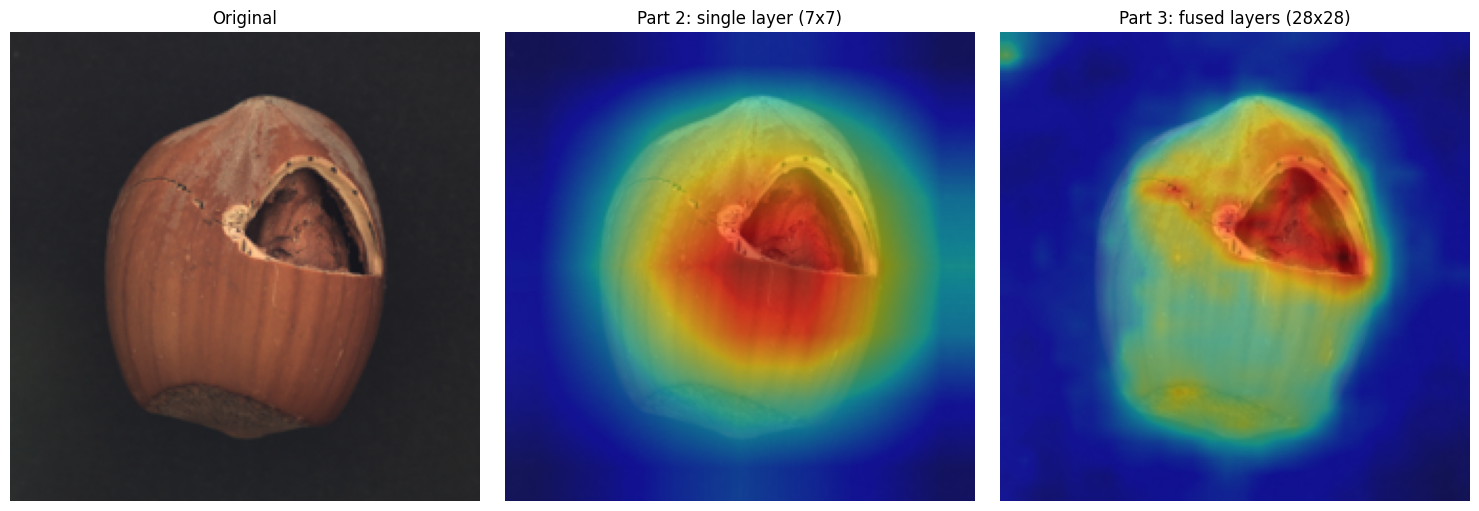

In [23]:
# Score the same CRACK image, but now with fused multi-layer features
crack_fused = extract_fused_features(crack_path).to(device)   # [784, 384]

# Distance from each of 784 regions to the whole bank
dists_fused = torch.cdist(crack_fused, fused_bank.to(device))  # [784, 306544]
region_scores_fused = dists_fused.min(dim=1).values            # [784]

# Reshape 784 -> 28x28, then upsample to 224x224
score_map_fused = region_scores_fused.reshape(1, 1, 28, 28)
score_map_fused = F.interpolate(score_map_fused, size=(224, 224), mode="bilinear", align_corners=False)
score_map_fused = score_map_fused.squeeze().cpu().numpy()

# Load original for overlay
orig_img = Image.open(crack_path).convert("RGB").resize((224, 224))

# Compare: Part 2 (7x7) vs Part 3 (28x28) side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(orig_img)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(orig_img)
axes[1].imshow(score_map, cmap="jet", alpha=0.5)          # score_map = old 7x7 result
axes[1].set_title("Part 2: single layer (7x7)")
axes[1].axis("off")

axes[2].imshow(orig_img)
axes[2].imshow(score_map_fused, cmap="jet", alpha=0.5)    # new 28x28 result
axes[2].set_title("Part 3: fused layers (28x28)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [24]:
# Score all test images using fused features; image score = MAX over its region scores
fused_scores = []
fused_labels = []

fused_bank_gpu = fused_bank.to(device)   # move bank to GPU once, reuse for all images

for cat in test_categories:
    for img_path in list_images(test_dir / cat):
        regions = extract_fused_features(img_path).to(device)   # [784, 384]
        dists = torch.cdist(regions, fused_bank_gpu)            # [784, 306544]
        region_scores = dists.min(dim=1).values                # [784]
        image_score = region_scores.max().item()               # MAX = image-level score
        fused_scores.append(image_score)
        fused_labels.append(0 if cat == "good" else 1)

fused_scores = torch.tensor(fused_scores)
fused_labels = torch.tensor(fused_labels)

# Compute AUC and compare with baseline
fused_auc = roc_auc_score(fused_labels.numpy(), fused_scores.numpy())

print(f"Baseline AUC (Part 1, whole-image): {auc:.4f}")
print(f"Fused AUC   (Part 3, max of regions): {fused_auc:.4f}")

Baseline AUC (Part 1, whole-image): 0.9625
Fused AUC   (Part 3, max of regions): 0.9971


In [25]:
# Choose a single global threshold using Youden's J statistic (best balance point on ROC)
fpr, tpr, thresholds = roc_curve(fused_labels.numpy(), fused_scores.numpy())

# Youden's J = TPR - FPR; the threshold that maximizes it is the best balance
youden_j = tpr - fpr
best_idx = youden_j.argmax()
threshold = thresholds[best_idx]

print(f"Selected threshold: {threshold:.3f}")
print(f"  -> catches {tpr[best_idx]*100:.1f}% of defects (TPR)")
print(f"  -> false alarms on {fpr[best_idx]*100:.1f}% of good ones (FPR)")

# Apply the threshold: predict defective if score > threshold
predictions = (fused_scores > threshold).int()
accuracy = (predictions == fused_labels).float().mean()
print(f"\nAccuracy at this threshold: {accuracy*100:.1f}%")

Selected threshold: 4.197
  -> catches 98.6% of defects (TPR)
  -> false alarms on 2.5% of good ones (FPR)

Accuracy at this threshold: 97.3%


In [26]:
def show_heatmaps(paths, titles):
    maps = []
    for path in paths:
        regions = extract_fused_features(path).to(device)
        dists = torch.cdist(regions, fused_bank_gpu)
        scores = dists.min(dim=1).values
        smap = scores.reshape(1, 1, 28, 28)
        smap = F.interpolate(smap, size=(224, 224), mode="bilinear", align_corners=False)
        maps.append(smap.squeeze().cpu().numpy())

    n = len(paths)
    fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))
    for j, (path, smap, title) in enumerate(zip(paths, maps, titles)):
        orig = Image.open(path).convert("RGB").resize((224, 224))
        axes[0, j].imshow(orig)
        axes[0, j].set_title(title)
        axes[0, j].axis("off")
        axes[1, j].imshow(orig)
        axes[1, j].imshow(smap, cmap="jet", alpha=0.5)
        axes[1, j].axis("off")
    plt.tight_layout()
    plt.show()

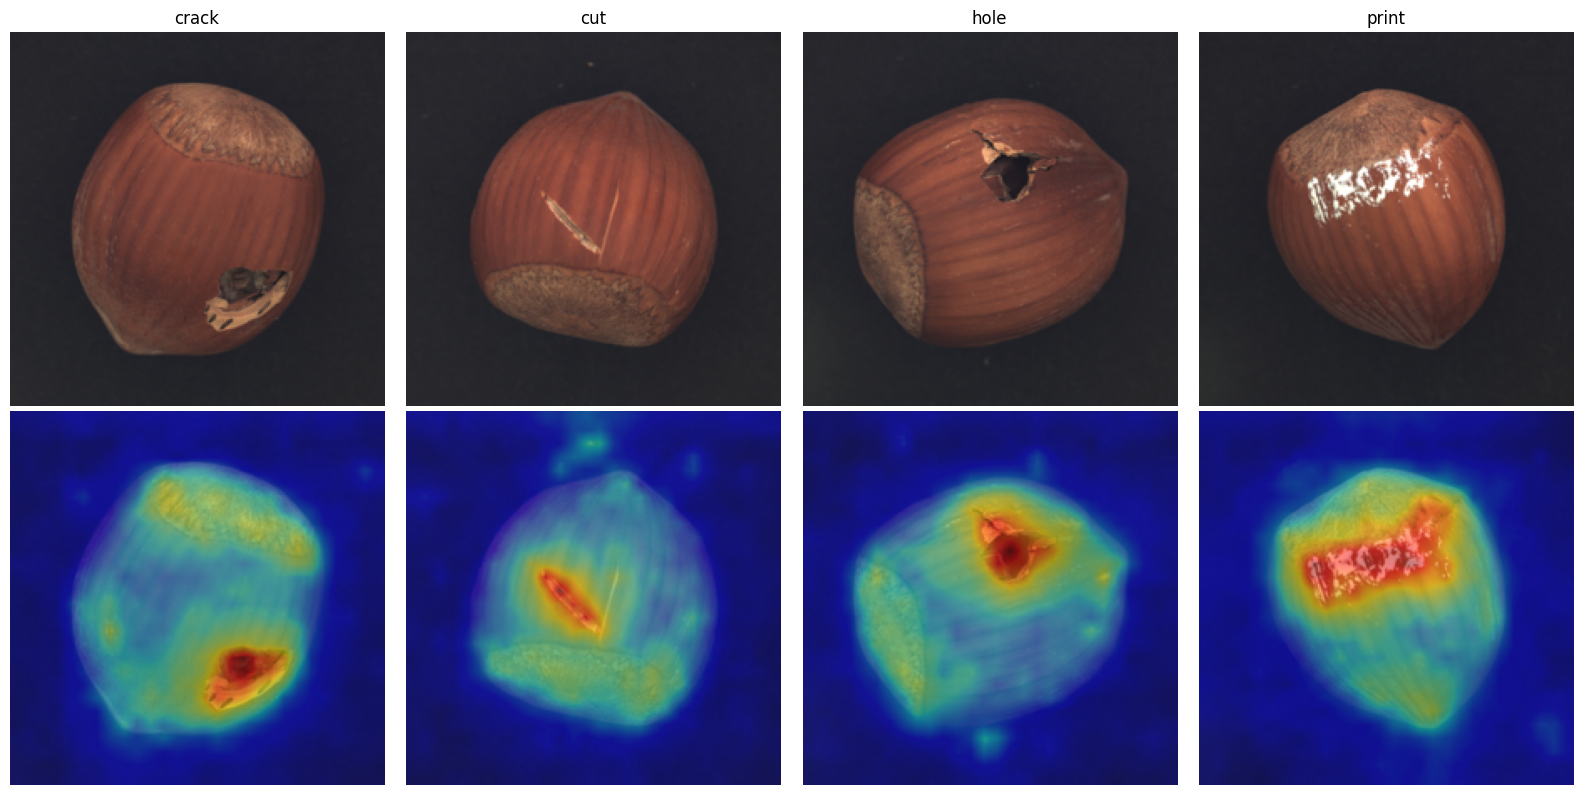

In [27]:
# Show heatmaps for the 4 defect types (good is covered by the accuracy metric)
defect_cats = [c for c in test_categories if c != "good"]

sample_paths = []
sample_titles = []
for cat in defect_cats:
    cat_paths = list_images(test_dir / cat)
    chosen = np.random.choice(cat_paths)
    sample_paths.append(chosen)
    sample_titles.append(cat)

show_heatmaps(sample_paths, sample_titles)